# CutPoint, walked through

Face shape from facial geometry, hairstyle recommendation, and the search behind
the catalogue.

Everything here imports from `backend/app`, so no logic is repeated and nothing
can drift from the code the 139 tests cover. It also runs without a single
photograph, because the classifier can be fed parametric faces built from
measurements.

**Where the numbers come from**

| Step | File | Holds |
|---|---|---|
| Catalogue | `backend/app/knowledge/hairstyles.yaml` | 21 styles with controlled vocabularies, validated on load |
| Geometry | `backend/app/services/face_geometry.py` | four measurements, three ratios |
| Classifier | `backend/app/services/face_classifier.py` | seven prototype faces |
| Ranking | `backend/app/services/recommend.py` | scoring and the reasons |
| Search | `backend/app/services/style_search.py` | TF-IDF over the catalogue |
| Charts | `tools/make_readme_figures.py` | `docs/figures/*.png` |

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('../backend'))

import numpy as np
import matplotlib.pyplot as plt

from app.knowledge.loader import load_styles
from app.services.face_geometry import compute_features
from app.services import face_classifier as fc
from app.services.recommend import recommend
from app.models.recommend import RecommendRequest

plt.rcParams.update({'figure.dpi': 110, 'font.size': 9})
print('ready')

ready


## 1. The catalogue

21 styles in a YAML file with controlled vocabularies. A typo fails at startup
rather than quietly producing an empty category, which is the whole reason for
validating on load rather than trusting the file.

In [2]:
styles = load_styles()
print('%d styles loaded\n' % len(styles))

s = styles[0]
for field in ('id', 'name', 'presentations', 'length', 'hair_types',
              'maintenance', 'flattering_for', 'rationale_tags'):
    print('%-16s %s' % (field, getattr(s, field, None)))

21 styles loaded

id               burst-fade
name             Burst Fade
presentations    [<Presentation.masculine: 'masculine'>]
length           Length.short
hair_types       [<HairType.curly: 'curly'>, <HairType.coily: 'coily'>, <HairType.wavy: 'wavy'>]
maintenance      Maintenance.medium
flattering_for   [<FaceShape.round: 'round'>, <FaceShape.oval: 'oval'>, <FaceShape.square: 'square'>, <FaceShape.diamond: 'diamond'>, <FaceShape.triangle: 'triangle'>]
rationale_tags   ['adds-texture', 'highlights-bone-structure']


`flattering_for` is what the recommender matches against, and `rationale_tags`
are what turn a match into a written reason rather than a bare score.

## 2. Face shape is measured, not predicted

Detection uses geometric ratios over MediaPipe's 468 facial landmarks: face
length, cheekbone width, jaw width, forehead width, and the jaw angle.

That is deliberate. The ratios are explainable, they need no training data, and
because they measure bone structure rather than hair they stay accurate on bald
and short haired faces, which is exactly where a hair trained classifier fails.

`build_face_landmarks` turns four measurements into a landmark set, which means
the classifier can be exercised without any photo at all. Here is an oval
face.

In [3]:
oval = fc.CANONICAL_FACES['oval']
print('measurements (pixels)')
for k in ('face_length', 'cheek_width', 'jaw_width', 'forehead_width'):
    print('  %-16s %.0f' % (k, getattr(oval, k)))

landmarks = fc.build_face_landmarks(oval)
feats = compute_features(landmarks, fc._IMAGE, fc._IMAGE)

print('\nratios, all normalised against cheekbone width')
for k in ('length_to_width', 'forehead_to_cheek', 'jaw_to_cheek', 'forehead_to_jaw'):
    print('  %-20s %.3f' % (k, getattr(feats, k)))

measurements (pixels)
  face_length      450
  cheek_width      300
  jaw_width        234
  forehead_width   270

ratios, all normalised against cheekbone width
  length_to_width      1.500
  forehead_to_cheek    0.900
  jaw_to_cheek         0.780
  forehead_to_jaw      1.154


Normalising against cheekbone width is what makes this independent of how close
the camera was. A face photographed from two metres and from half a metre gives
the same ratios.

## 3. Does the classifier recover its own prototypes?

The obvious first check. Build each of the seven prototype faces, run the real
classifier, and see what comes back.

In [4]:
shapes = ['oval', 'round', 'square', 'oblong', 'heart', 'diamond', 'triangle']

print('%-10s %-10s %10s' % ('built as', 'classified', 'confidence'))
print('-' * 34)
correct = 0
for name in shapes:
    lm = fc.build_face_landmarks(fc.CANONICAL_FACES[name])
    res = fc.classify(compute_features(lm, fc._IMAGE, fc._IMAGE))
    ok = res.shape == name
    correct += ok
    print('%-10s %-10s %9.2f  %s' % (name, res.shape, res.confidence, '' if ok else '<- wrong'))

print('\n%d of %d recovered' % (correct, len(shapes)))

built as   classified confidence
----------------------------------
oval       oval            0.53  
round      round           0.67  
square     square          0.77  
oblong     oblong          0.79  
heart      heart           0.93  
diamond    diamond         0.65  
triangle   triangle        0.98  

7 of 7 recovered


Seven out of seven, which is the least it could do. A prototype failing to
classify as itself would mean the feature vector and the distance function
disagree.

This is a sanity check rather than evidence of accuracy. The interesting question
is what happens when a face is **not** a textbook example.

## 4. What happens between two shapes

Real faces sit between the prototypes. Here is a face morphed continuously from
round to oblong, with everything else held fixed.

In [5]:
round_f, oblong_f = fc.CANONICAL_FACES['round'], fc.CANONICAL_FACES['oblong']
steps = np.linspace(0, 1, 21)

rows = []
for t in steps:
    face = fc.CanonicalFace(
        face_length   = round_f.face_length   * (1-t) + oblong_f.face_length   * t,
        cheek_width   = round_f.cheek_width   * (1-t) + oblong_f.cheek_width   * t,
        jaw_width     = round_f.jaw_width     * (1-t) + oblong_f.jaw_width     * t,
        forehead_width= round_f.forehead_width* (1-t) + oblong_f.forehead_width* t)
    lm = fc.build_face_landmarks(face)
    f = compute_features(lm, fc._IMAGE, fc._IMAGE)
    res = fc.classify(f)
    rows.append((t, f.length_to_width, res.shape, res.confidence))

print('%6s %10s  %-10s %s' % ('morph', 'len/cheek', 'called it', 'confidence'))
print('-' * 44)
for t, ratio, shape, conf in rows[::2]:
    print('%6.2f %10.2f  %-10s %.2f' % (t, ratio, shape, conf))

 morph  len/cheek  called it  confidence
--------------------------------------------
  0.00       1.05  round      0.67
  0.10       1.12  round      0.58
  0.20       1.19  round      0.48
  0.30       1.26  round      0.38
  0.40       1.33  oval       0.36
  0.50       1.40  oval       0.39
  0.60       1.47  oval       0.39
  0.70       1.54  oblong     0.44
  0.80       1.61  oblong     0.58
  0.90       1.68  oblong     0.70
  1.00       1.75  oblong     0.79


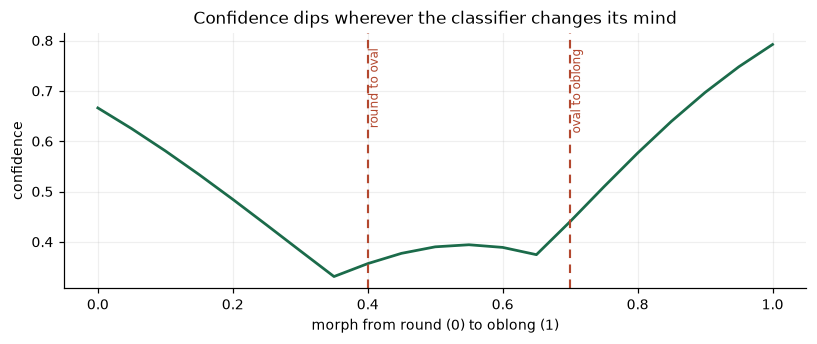

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ts   = [r[0] for r in rows]
conf = [r[3] for r in rows]
shape_at = [r[2] for r in rows]

boundaries = [i for i in range(1, len(shape_at)) if shape_at[i] != shape_at[i-1]]
ax.plot(ts, conf, color='#1b6b4a', lw=1.8)
for b in boundaries:
    ax.axvline(ts[b], color='#b3482f', ls=(0,(4,3)), lw=1.4)
    ax.text(ts[b], max(conf)*0.99, ' %s to %s' % (shape_at[b-1], shape_at[b]),
            fontsize=8, color='#b3482f', va='top', rotation=90)
ax.set_xlabel('morph from round (0) to oblong (1)')
ax.set_ylabel('confidence')
ax.set_title('Confidence dips wherever the classifier changes its mind', fontsize=11)
for s in ('top','right'): ax.spines[s].set_visible(False)
ax.grid(alpha=.2); plt.tight_layout(); plt.show()

Confidence is lowest right where the classifier changes its mind, which is what
it should do. A face genuinely on the boundary between two shapes is not a
confident call, and the number says so rather than hiding it.

That matters for the product: a borderline face can be shown styles from both
shapes instead of being forced into one.

## 5. From a shape to a recommendation

Ranking scores each style against the detected shape and the stated preferences,
and reports which preferences it satisfied. Nothing is a black box.

In [7]:
req = RecommendRequest(face_shape='round', presentation='masculine',
                       desired_length='short', maintenance='low', limit=5)
res = recommend(req)

for i, item in enumerate(res.recommendations, 1):
    print('%d. %-24s match %.2f   %s / %s upkeep'
          % (i, item.name, item.match_score, item.length.value, item.maintenance.value))
    print('      satisfied : %s' % ', '.join(item.matched_on))
    print('      why it works: %s' % ', '.join(item.rationale_tags))
    print()

1. Edgar Cut                match 1.00   short / low upkeep
      satisfied : face_shape, length, maintenance
      why it works: shortens-face, adds-texture

2. Burst Fade               match 0.80   short / medium upkeep
      satisfied : face_shape, length
      why it works: adds-texture, highlights-bone-structure

3. Textured Fringe          match 0.80   short / medium upkeep
      satisfied : face_shape, length
      why it works: shortens-face, balances-forehead, adds-texture

4. Middle-Part Curtains     match 0.50   medium / medium upkeep
      satisfied : face_shape
      why it works: adds-texture, softens-angles

5. Modern Mullet            match 0.50   medium / medium upkeep
      satisfied : face_shape
      why it works: adds-texture, adds-volume



Every result carries its reasons. That is the difference between a recommender a
user trusts and one they argue with.

## 6. How much choice each shape actually gets

A fair question to ask of any catalogue: is it equally useful to everyone?

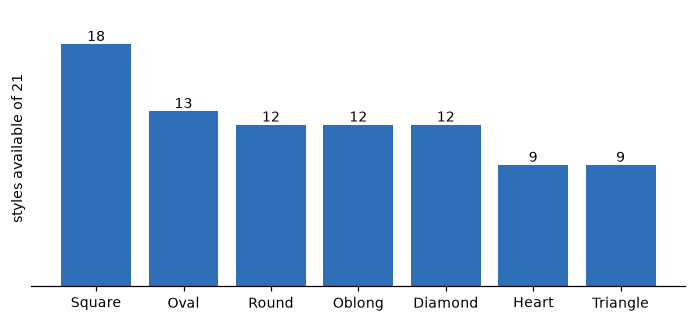

Square has the widest choice at 18 of 21.
Triangle has the fewest at 9.

A thin column is a gap in the catalogue, not a weakness in the matching.
The same ratios are measured either way.


In [8]:
per_shape = {sh: sum(sh in st.flattering_for for st in styles) for sh in shapes}
order = sorted(per_shape.items(), key=lambda kv: -kv[1])

fig, ax = plt.subplots(figsize=(6.4, 3.0))
ax.bar([k.capitalize() for k, _ in order], [v for _, v in order], color='#2f6fb8')
for i, (_, v) in enumerate(order):
    ax.text(i, v + 0.25, str(v), ha='center', fontsize=9)
ax.set_ylabel('styles available of %d' % len(styles))
ax.set_ylim(0, max(per_shape.values()) + 2.5)
for s in ('top','right','left'): ax.spines[s].set_visible(False)
ax.set_yticks([]); plt.tight_layout(); plt.show()

top, low = order[0], order[-1]
print('%s has the widest choice at %d of %d.' % (top[0].capitalize(), top[1], len(styles)))
print('%s has the fewest at %d.' % (low[0].capitalize(), low[1]))
print()
print('A thin column is a gap in the catalogue, not a weakness in the matching.')
print('The same ratios are measured either way.')

## 7. Search, and why there is no vector database

A free text query is turned into the catalogue's own controlled vocabulary, then
retrieval runs over a TF-IDF index built at startup.

The index covers **21 documents**. A vector database would be weight without
benefit at that size, and it would add a service to deploy and keep alive. This
is the kind of decision worth making explicitly rather than by habit.

In [9]:
from app.services.style_search import _tokens

doc = '%s %s %s %s' % (styles[0].name, styles[0].description,
                       ' '.join(styles[0].hair_types),
                       ' '.join(styles[0].rationale_tags))
print('a catalogue document, tokenised:')
print(' ', _tokens(doc)[:18], '...')
print()
print('corpus size: %d documents' % len(styles))
print('a TF-IDF index over 21 documents fits in memory and needs no service.')

a catalogue document, tokenised:
  ['burst', 'fade', 'fade', 'curves', 'around', 'ear', 'textured', 'length', 'left', 'top', 'curly', 'coily', 'wavy', 'adds', 'texture', 'highlights', 'bone', 'structure'] ...

corpus size: 21 documents
a TF-IDF index over 21 documents fits in memory and needs no service.


## 8. Privacy is a design decision, not a policy page

Landmark detection runs in the browser using MediaPipe. The backend receives
derived ratios, never a photograph, unless the user explicitly asks for a server
side try on, and then it receives only that one image.

The whole of this notebook is a demonstration of why that is possible: the
classifier never needs a photo, only four measurements.

## 9. What this does not do

- The 2D try on is a landmark anchored overlay, not a neural render.
- The four angle views are reference images of each hairstyle, not a
  reconstruction of the user's own head. A single front photo cannot give a real
  back of head view, so the app does not invent one.
- Face shape prototypes are anthropometric reference values, not a population
  study. They classify consistently. They are not a clinical measurement.
- A single primary face is assumed, with specific messaging for no face,
  multiple faces, low quality and non frontal photos.

---

**To run the whole thing:**

```bash
docker compose up -d
cd backend && uvicorn app.main:app --reload
cd frontend && npm run dev
pytest -q                            # 139 passed
```